# FIREGUARD ID — 03: Baseline Unsupervised Modeling (K-Means)

            - Module: `src/models/kmeans_model.py` (`run_kmeans_pipeline`) & `src/evaluation/metrics.py`.
            - Sweeps `k` in `[2, 3, 4, 5, 6, 7, 8]` on the identical locked 4-feature matrix (`853` cells).
            - Evaluates Silhouette, Davies-Bouldin, Calinski-Harabasz, cluster size balance (`min_cluster_share >= 0.05`), 5-seed stability (`ARI`), spatial coherence, and leave-one-quadrant-out spatial transfer.


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

import joblib
from src.evaluation.metrics import compute_clustering_metrics, compute_spatial_coherence
from src.models.kmeans_model import run_kmeans_pipeline


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Load Experiment Registry & Verify Metrics Live


In [2]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
models_dir = resolve_path(proj_cfg["paths"]["models_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)

df_scaled = pd.read_parquet(processed_dir / "clustering_matrix_scaled.parquet")
feat_cols = [c for c in df_scaled.columns if c != "grid_id"]
X = df_scaled[feat_cols].to_numpy(dtype=float)

df_km = pd.read_parquet(models_dir / "kmeans" / "kmeans_assignments.parquet")
km_model = joblib.load(models_dir / "kmeans" / "kmeans_model.joblib")
km_exp = json.loads((reports_dir / "clustering" / "kmeans_experiments.json").read_text(encoding="utf-8"))

live_metrics = compute_clustering_metrics(X, df_km["cluster_kmeans"].to_numpy(), exclude_noise_label=None)
print("Selected k:", km_exp["selection"]["selected_k"])
print("Live verified metrics:", json.dumps(live_metrics, indent=2))
print("Multi-seed ARI:", km_exp["selected_model_summary"]["multi_seed_stability"])
print("Spatial generalization:", km_exp["selected_model_summary"]["spatial_generalization"])


Selected k: 3
Live verified metrics: {
  "n_total": 853,
  "n_valid_clustered": 853,
  "n_clusters": 3,
  "n_noise": 0,
  "noise_ratio": 0.0,
  "valid_for_internal_metrics": true,
  "reason": "ok",
  "silhouette_score": 0.544178,
  "davies_bouldin_index": 0.714354,
  "calinski_harabasz_index": 1261.715,
  "cluster_sizes": {
    "0": 329,
    "1": 446,
    "2": 78
  },
  "min_cluster_share": 0.091442,
  "max_cluster_share": 0.52286
}
Multi-seed ARI: {'mean_ari': 1.0, 'min_ari': 1.0, 'mean_nmi': 1.0, 'n_pairs': 10}
Spatial generalization: {'n_folds': 4, 'mean_test_silhouette': 0.537214, 'mean_test_davies_bouldin': 0.708193, 'mean_test_calinski_harabasz': 305.6712, 'mean_transfer_ari': 0.972507, 'min_transfer_ari': 0.929049, 'mean_transfer_nmi': 0.949837}


## 2. Candidate Sweep (`k=2..8`) & Centroid Inspection


,k,silhouette,davies_bouldin,calinski_harabasz,min_share,seed_mean_ari,spatial_transfer_ari
0,2,0.543706,0.807048,968.7602,0.315358,1.000000,0.972086
1,3,0.544178,0.714354,1261.7150,0.091442,1.000000,0.972507
2,4,0.524246,0.805993,1287.9740,0.057444,0.982952,0.929674
3,5,0.516500,0.819181,1316.8184,0.037515,0.995779,0.948137
4,6,0.534711,0.825204,1270.2806,0.038687,0.999050,0.871176
5,7,0.550538,0.779690,1234.8868,0.036342,0.986055,0.970872
6,8,0.551179,0.770737,1192.9841,0.003517,0.986463,0.887381


,cluster_kmeans,n_cells,cell_share,zero_detection_cells,total_hotspots,hotspot_share,centroid_scaled_hotspot_density_km2,centroid_raw_hotspot_density_km2,mean_hotspot_density_km2,median_hotspot_density_km2,...,median_active_years_count,centroid_scaled_frp_total_density_mw_km2,centroid_raw_frp_total_density_mw_km2,mean_frp_total_density_mw_km2,median_frp_total_density_mw_km2,mean_hotspot_count,mean_active_months_count,mean_frp_mw_when_active,mean_dry_season_share_when_active,qa_mean_high_conf_share_when_active
0,0,329,0.385698,0,5331,0.343714,0.032710,0.143505,0.149738,0.101770,...,3.0,0.115734,0.597201,0.727793,0.397392,16.2036,7.1064,4.8788,0.6124,0.0101
1,1,446,0.522860,249,470,0.030303,-0.478357,0.012266,0.012745,0.000000,...,0.0,-0.538139,0.051960,0.060711,0.000000,1.0538,0.6749,4.8494,0.6297,0.0047
2,2,78,0.091442,0,9709,0.625983,2.597251,1.108192,1.252001,0.905897,...,5.0,2.588893,6.750384,8.437494,6.263328,124.4744,14.2692,7.8516,0.7279,0.0280


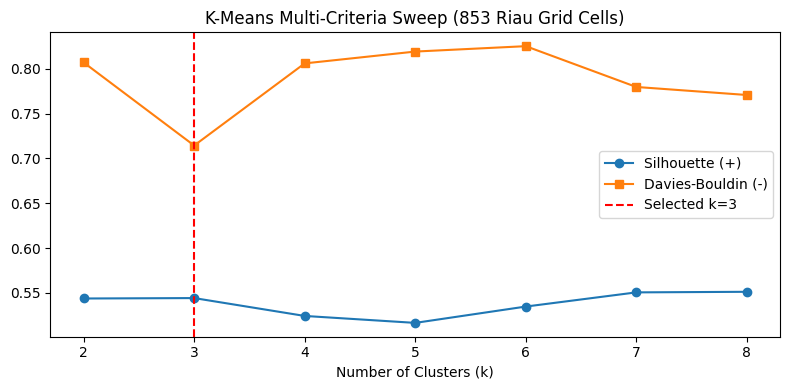

In [3]:
sweep_rows = []
for row in km_exp["sweep_results"]:
    im = row["internal_metrics"]
    sweep_rows.append({
        "k": row["k"],
        "silhouette": im["silhouette_score"],
        "davies_bouldin": im["davies_bouldin_index"],
        "calinski_harabasz": im["calinski_harabasz_index"],
        "min_share": im["min_cluster_share"],
        "seed_mean_ari": row["multi_seed_stability"]["mean_ari"],
        "spatial_transfer_ari": row["spatial_generalization"]["mean_transfer_ari"],
    })
sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)

centroids = pd.read_csv(models_dir / "kmeans" / "kmeans_centroids.csv")
display(centroids)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep_df["k"], sweep_df["silhouette"], marker="o", label="Silhouette (+)")
ax.plot(sweep_df["k"], sweep_df["davies_bouldin"], marker="s", label="Davies-Bouldin (-)")
ax.axvline(km_exp["selection"]["selected_k"], color="red", linestyle="--", label="Selected k=3")
ax.set_xlabel("Number of Clusters (k)")
ax.set_title("K-Means Multi-Criteria Sweep (853 Riau Grid Cells)")
ax.legend()
plt.tight_layout()
plt.show()
